In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)

from sklearn.linear_model import LogisticRegression

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
TRAIN_PATH = "data/train.csv"
TEST_PATH = "data/test.csv"
SAMPLE_PATH = "data/sample_submission.csv"

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
sample_submission = pd.read_csv(SAMPLE_PATH)

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Sample submission shape:", sample_submission.shape)

Train shape: (800, 12)
Test shape: (400, 11)
Sample submission shape: (400, 2)


In [3]:
pd.set_option("display.max_columns", None)

train.head()

,wedding_id,event,city,guests,aloo_count,mutton_kg,borhani_glasses,fairy_lights,drone_photographer,dhol_players,aunties_asking_when_marriage,went_back_for_seconds
0,W0001,Gaye Holud,Barishal,604,1327.0,138.1,529,478,no,6,8,0
1,W0002,Bou-bhat,Dhaka,166,104.0,35.0,172,445,yes,3,3,0
2,W0003,Biye,Mymensingh,67,59.0,16.7,72,116,yes,2,3,0
3,W0004,Biye,Dhaka,466,1206.0,122.3,668,1586,no,1,4,0
4,W0005,Biye,Khulna,287,209.0,81.9,278,646,yes,0,9,0


In [4]:
test.head()

,wedding_id,event,city,guests,aloo_count,mutton_kg,borhani_glasses,fairy_lights,drone_photographer,dhol_players,aunties_asking_when_marriage
0,W0801,Biye,Chattogram,1235,3010,228.3,1766,980,yes,3,3
1,W0802,Biye,Dhaka,426,868,125.2,525,852,no,3,9
2,W0803,Bou-bhat,Dhaka,656,1319,140.2,855,922,no,1,5
3,W0804,Biye,Dhaka,852,1009,247.6,705,1232,yes,7,5
4,W0805,Gaye Holud,Khulna,532,1315,156.6,520,1415,no,0,9


In [5]:
sample_submission.head()

,wedding_id,went_back_for_seconds
0,W0801,0
1,W0802,0
2,W0803,0
3,W0804,0
4,W0805,0


In [7]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 12 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   wedding_id                    800 non-null    object 
 1   event                         800 non-null    object 
 2   city                          800 non-null    object 
 3   guests                        800 non-null    int64  
 4   aloo_count                    776 non-null    float64
 5   mutton_kg                     800 non-null    float64
 6   borhani_glasses               800 non-null    int64  
 7   fairy_lights                  800 non-null    object 
 8   drone_photographer            800 non-null    object 
 9   dhol_players                  800 non-null    int64  
 10  aunties_asking_when_marriage  800 non-null    int64  
 11  went_back_for_seconds         800 non-null    int64  
dtypes: float64(2), int64(5), object(5)
memory usage: 75.1+ KB


In [8]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 11 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   wedding_id                    400 non-null    object 
 1   event                         400 non-null    object 
 2   city                          400 non-null    object 
 3   guests                        400 non-null    int64  
 4   aloo_count                    400 non-null    int64  
 5   mutton_kg                     400 non-null    float64
 6   borhani_glasses               400 non-null    int64  
 7   fairy_lights                  400 non-null    int64  
 8   drone_photographer            400 non-null    object 
 9   dhol_players                  400 non-null    int64  
 10  aunties_asking_when_marriage  400 non-null    int64  
dtypes: float64(1), int64(6), object(4)
memory usage: 34.5+ KB


In [9]:
train.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
wedding_id,800,800,W0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event,800,3,Biye,378,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,800,8,Dhaka,262,NaN,NaN,NaN,NaN,NaN,NaN,NaN
guests,800.0,NaN,NaN,NaN,371.62375,184.408379,51.0,219.5,367.0,531.0,700.0
aloo_count,776.0,NaN,NaN,NaN,626.070876,781.629417,28.0,262.75,471.5,850.0,11520.0
mutton_kg,800.0,NaN,NaN,NaN,94.35,49.023904,9.3,54.4,92.9,128.425,221.3
borhani_glasses,800.0,NaN,NaN,NaN,428.31875,230.407713,45.0,241.0,411.0,597.0,1016.0
fairy_lights,800,662,1021,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
drone_photographer,800,2,no,481,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dhol_players,800.0,NaN,NaN,NaN,4.005,2.575513,0.0,2.0,4.0,6.0,8.0


In [10]:
print("TRAIN MISSING VALUES")
print(train.isna().sum())

print("\nTEST MISSING VALUES")
print(test.isna().sum())

TRAIN MISSING VALUES
wedding_id                       0
event                            0
city                             0
guests                           0
aloo_count                      24
mutton_kg                        0
borhani_glasses                  0
fairy_lights                     0
drone_photographer               0
dhol_players                     0
aunties_asking_when_marriage     0
went_back_for_seconds            0
dtype: int64

TEST MISSING VALUES
wedding_id                      0
event                           0
city                            0
guests                          0
aloo_count                      0
mutton_kg                       0
borhani_glasses                 0
fairy_lights                    0
drone_photographer              0
dhol_players                    0
aunties_asking_when_marriage    0
dtype: int64


In [11]:
target = "went_back_for_seconds"

print(train[target].value_counts())
print()
print(train[target].value_counts(normalize=True))

went_back_for_seconds
0    464
1    336
Name: count, dtype: int64

went_back_for_seconds
0    0.58
1    0.42
Name: proportion, dtype: float64


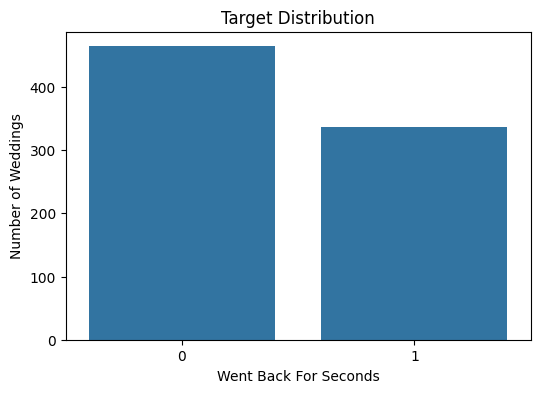

In [12]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=train,
    x=target
)

plt.title("Target Distribution")
plt.xlabel("Went Back For Seconds")
plt.ylabel("Number of Weddings")

plt.show()

In [13]:
categorical_columns = [
    "event",
    "city",
    "drone_photographer"
]

for col in categorical_columns:
    print("=" * 60)
    print(col)
    print(train[col].value_counts())

event
event
Biye          378
Gaye Holud    238
Bou-bhat      184
Name: count, dtype: int64
city
city
Dhaka         262
Chattogram    118
Rajshahi      100
Khulna         87
Sylhet         69
Barishal       66
Rangpur        60
Mymensingh     38
Name: count, dtype: int64
drone_photographer
drone_photographer
no     481
yes    319
Name: count, dtype: int64


In [14]:
numeric_columns = [
    "guests",
    "aloo_count",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage"
]

train[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
guests,800.0,371.623750,184.408379,51.0,219.50,367.0,531.000,700.0
aloo_count,776.0,626.070876,781.629417,28.0,262.75,471.5,850.000,11520.0
mutton_kg,800.0,94.350000,49.023904,9.3,54.40,92.9,128.425,221.3
borhani_glasses,800.0,428.318750,230.407713,45.0,241.00,411.0,597.000,1016.0
dhol_players,800.0,4.005000,2.575513,0.0,2.00,4.0,6.000,8.0
aunties_asking_when_marriage,800.0,5.996250,2.491786,1.0,4.00,6.0,8.000,16.0


In [15]:
print(train["fairy_lights"].head(20).tolist())
print(test["fairy_lights"].head(20).tolist())

['478', '445', '116', '1586', '646', '780', '৩৯৯', '618', '1020', '527', '979', '1383', '1448', '2152', '1398', '685', '1951', '578', '196', '889']
[980, 852, 922, 1232, 1415, 966, 1641, 2479, 2456, 413, 3009, 306, 4223, 1246, 1239, 1448, 4017, 712, 1368, 4583]


In [16]:
bangla_to_english = str.maketrans(
    "০১২৩৪৫৬৭৮৯",
    "0123456789"
)

for df in [train, test]:
    df["fairy_lights"] = (
        df["fairy_lights"]
        .astype(str)
        .str.translate(bangla_to_english)
        .astype(int)
    )

print("Bangla digit conversion completed.")

Bangla digit conversion completed.


In [17]:
print("Train missing aloo:", train["aloo_count"].isna().sum())
print("Test missing aloo:", test["aloo_count"].isna().sum())

Train missing aloo: 24
Test missing aloo: 0


In [18]:
train[train["aloo_count"].isna()]

,wedding_id,event,city,guests,aloo_count,mutton_kg,borhani_glasses,fairy_lights,drone_photographer,dhol_players,aunties_asking_when_marriage,went_back_for_seconds
9,W0010,Gaye Holud,Dhaka,281,NaN,54.4,328,527,yes,6,4,0
21,W0022,Biye,Sylhet,679,NaN,149.7,887,570,no,4,7,0
40,W0041,Biye,Sylhet,605,NaN,111.0,513,2015,no,2,10,1
51,W0052,Gaye Holud,Dhaka,287,NaN,56.2,305,843,no,3,6,0
176,W0177,Gaye Holud,Dhaka,353,NaN,84.0,523,1247,yes,3,7,1
233,W0234,Gaye Holud,Rajshahi,104,NaN,23.8,125,180,no,1,8,0
255,W0256,Bou-bhat,Barishal,583,NaN,161.2,611,1444,yes,5,7,1
258,W0259,Biye,Khulna,268,NaN,60.3,399,1178,yes,6,8,1
293,W0294,Gaye Holud,Rangpur,123,NaN,34.4,170,487,no,4,9,1
295,W0296,Biye,Barishal,289,NaN,83.6,347,1097,no,8,6,0


In [19]:
train.loc[
    train["aloo_count"].isna(),
    ["wedding_id", "guests", "mutton_kg", target]
]

,wedding_id,guests,mutton_kg,went_back_for_seconds
9,W0010,281,54.4,0
21,W0022,679,149.7,0
40,W0041,605,111.0,1
51,W0052,287,56.2,0
176,W0177,353,84.0,1
233,W0234,104,23.8,0
255,W0256,583,161.2,1
258,W0259,268,60.3,1
293,W0294,123,34.4,1
295,W0296,289,83.6,0


In [20]:
train[
    [
        "wedding_id",
        "guests",
        "aloo_count",
        "mutton_kg",
        target
    ]
].sort_values(
    "aloo_count",
    ascending=False
).head(30)

,wedding_id,guests,aloo_count,mutton_kg,went_back_for_seconds
501,W0502,695,11520.0,126.7,1
785,W0786,439,10270.0,106.0,0
671,W0672,311,8320.0,59.0,0
80,W0081,315,7150.0,96.0,0
447,W0448,396,6520.0,116.3,1
674,W0675,686,1831.0,191.9,0
556,W0557,659,1764.0,185.9,0
744,W0745,665,1739.0,128.5,0
677,W0678,675,1732.0,158.5,0
545,W0546,700,1712.0,130.4,0


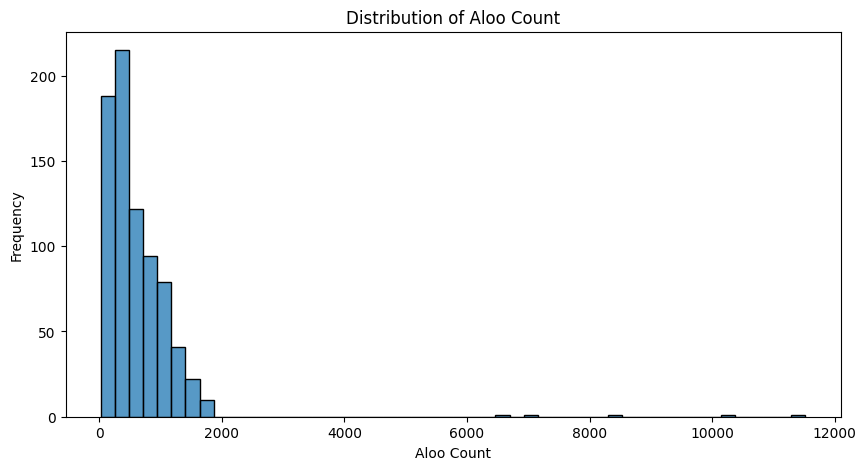

In [21]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=train,
    x="aloo_count",
    bins=50
)

plt.title("Distribution of Aloo Count")
plt.xlabel("Aloo Count")
plt.ylabel("Frequency")

plt.show()

In [22]:
train["aloo_per_guest"] = (
    train["aloo_count"] / train["guests"]
)

test["aloo_per_guest"] = (
    test["aloo_count"] / test["guests"]
)

In [23]:
train[
    [
        "guests",
        "aloo_count",
        "aloo_per_guest",
        target
    ]
].head(20)

,guests,aloo_count,aloo_per_guest,went_back_for_seconds
0,604,1327.0,2.197020,0
1,166,104.0,0.626506,0
2,67,59.0,0.880597,0
3,466,1206.0,2.587983,0
4,287,209.0,0.728223,0
5,354,738.0,2.084746,0
6,101,136.0,1.346535,1
7,291,703.0,2.415808,0
8,468,261.0,0.557692,0
9,281,NaN,NaN,0


In [24]:
train.groupby(target)["aloo_per_guest"].describe()

,count,mean,std,min,25%,50%,75%,max
went_back_for_seconds,,,,,,,,
0,448.0,1.741274,2.076591,0.406015,0.729030,2.018412,2.361526,26.752412
1,328.0,1.576235,1.212135,0.940426,1.217525,1.460769,1.753228,16.575540


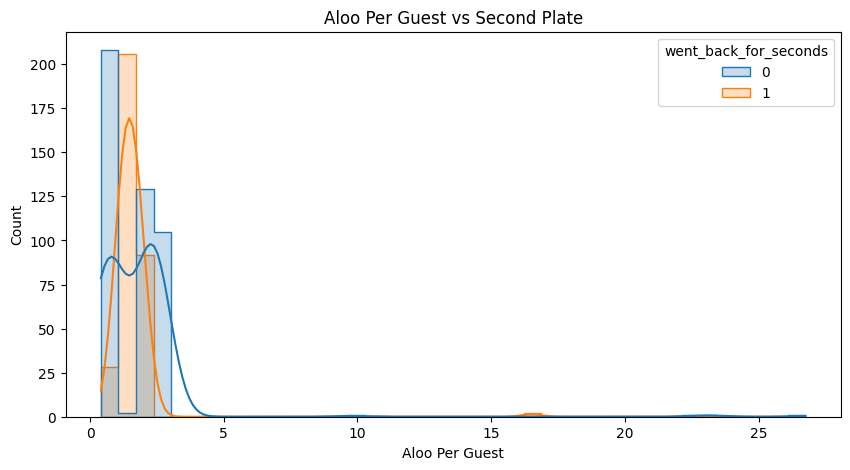

In [25]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=train,
    x="aloo_per_guest",
    hue=target,
    bins=40,
    kde=True,
    element="step"
)

plt.title("Aloo Per Guest vs Second Plate")
plt.xlabel("Aloo Per Guest")
plt.ylabel("Count")

plt.show()

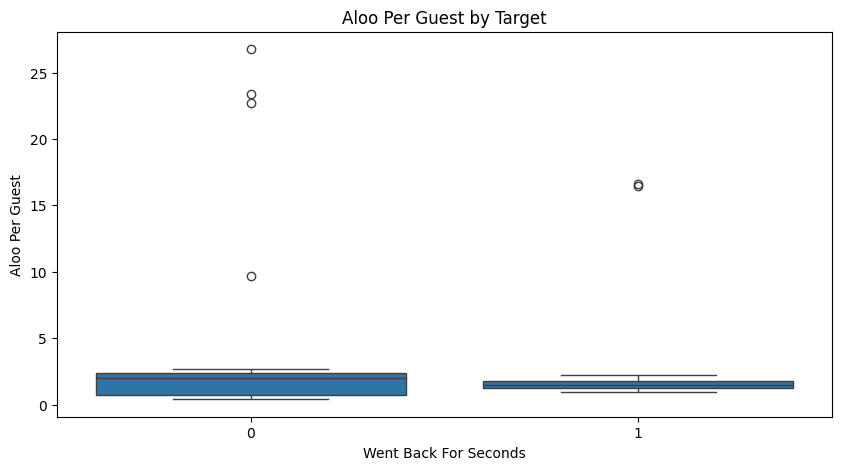

In [26]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=train,
    x=target,
    y="aloo_per_guest"
)

plt.title("Aloo Per Guest by Target")
plt.xlabel("Went Back For Seconds")
plt.ylabel("Aloo Per Guest")

plt.show()

In [27]:
train["aloo_count"].describe()

count      776.000000
mean       626.070876
std        781.629417
min         28.000000
25%        262.750000
50%        471.500000
75%        850.000000
max      11520.000000
Name: aloo_count, dtype: float64

In [28]:
train.loc[
    train["aloo_count"].isna(),
    ["wedding_id", "guests", "mutton_kg", target]
]


,wedding_id,guests,mutton_kg,went_back_for_seconds
9,W0010,281,54.4,0
21,W0022,679,149.7,0
40,W0041,605,111.0,1
51,W0052,287,56.2,0
176,W0177,353,84.0,1
233,W0234,104,23.8,0
255,W0256,583,161.2,1
258,W0259,268,60.3,1
293,W0294,123,34.4,1
295,W0296,289,83.6,0


In [29]:
train[
    ["wedding_id", "guests", "aloo_count", "mutton_kg", target]
].sort_values(
    "aloo_count",
    ascending=False
).head(30)

,wedding_id,guests,aloo_count,mutton_kg,went_back_for_seconds
501,W0502,695,11520.0,126.7,1
785,W0786,439,10270.0,106.0,0
671,W0672,311,8320.0,59.0,0
80,W0081,315,7150.0,96.0,0
447,W0448,396,6520.0,116.3,1
674,W0675,686,1831.0,191.9,0
556,W0557,659,1764.0,185.9,0
744,W0745,665,1739.0,128.5,0
677,W0678,675,1732.0,158.5,0
545,W0546,700,1712.0,130.4,0


In [30]:
train.groupby(target)["aloo_per_guest"].describe()

,count,mean,std,min,25%,50%,75%,max
went_back_for_seconds,,,,,,,,
0,448.0,1.741274,2.076591,0.406015,0.729030,2.018412,2.361526,26.752412
1,328.0,1.576235,1.212135,0.940426,1.217525,1.460769,1.753228,16.575540


In [31]:
train["aloo_per_guest"].describe(
    percentiles=[
        0.01,
        0.05,
        0.10,
        0.20,
        0.25,
        0.50,
        0.75,
        0.80,
        0.90,
        0.95,
        0.99
    ]
)

count    776.000000
mean       1.671515
std        1.764589
min        0.406015
1%         0.420746
5%         0.506106
10%        0.627647
20%        0.827465
25%        0.957247
50%        1.507989
75%        2.132390
80%        2.242175
90%        2.505978
95%        2.613339
99%        2.698749
max       26.752412
Name: aloo_per_guest, dtype: float64

In [32]:
train[
    [
        "wedding_id",
        "guests",
        "aloo_count",
        "aloo_per_guest",
        "went_back_for_seconds"
    ]
].sort_values(
    "aloo_per_guest"
).head(40)

,wedding_id,guests,aloo_count,aloo_per_guest,went_back_for_seconds
311,W0312,133,54.0,0.406015,0
699,W0700,559,228.0,0.407871,0
167,W0168,110,45.0,0.409091,0
502,W0503,68,28.0,0.411765,0
184,W0185,216,90.0,0.416667,0
281,W0282,443,185.0,0.417607,0
718,W0719,253,106.0,0.418972,0
471,W0472,290,122.0,0.420690,0
747,W0748,366,154.0,0.420765,0
70,W0071,351,149.0,0.424501,0


In [33]:
train[
    [
        "wedding_id",
        "guests",
        "aloo_count",
        "aloo_per_guest",
        "went_back_for_seconds"
    ]
].sort_values(
    "aloo_per_guest",
    ascending=False
).head(40)

,wedding_id,guests,aloo_count,aloo_per_guest,went_back_for_seconds
671,W0672,311,8320.0,26.752412,0
785,W0786,439,10270.0,23.394077,0
80,W0081,315,7150.0,22.698413,0
501,W0502,695,11520.0,16.575540,1
447,W0448,396,6520.0,16.464646,1
316,W0317,133,1290.0,9.699248,0
115,W0116,320,864.0,2.700000,0
519,W0520,413,1115.0,2.699758,0
28,W0029,126,340.0,2.698413,0
217,W0218,459,1238.0,2.697168,0


In [34]:
bins = [
    0,
    0.5,
    0.75,
    0.9,
    1.0,
    1.1,
    1.2,
    1.3,
    1.4,
    1.5,
    1.6,
    1.7,
    1.8,
    2.0,
    2.25,
    2.5,
    3.0,
    4.0,
    10.0,
    np.inf
]

train["aloo_ratio_bin"] = pd.cut(
    train["aloo_per_guest"],
    bins=bins,
    include_lowest=True
)

ratio_analysis = (
    train.groupby("aloo_ratio_bin", observed=False)
    .agg(
        weddings=("went_back_for_seconds", "size"),
        seconds=("went_back_for_seconds", "sum"),
        second_rate=("went_back_for_seconds", "mean")
    )
)

ratio_analysis

,weddings,seconds,second_rate
aloo_ratio_bin,,,
"(-0.001, 0.5]",37,0,0.000000
"(0.5, 0.75]",85,0,0.000000
"(0.75, 0.9]",55,0,0.000000
"(0.9, 1.0]",37,12,0.324324
"(1.0, 1.1]",31,25,0.806452
"(1.1, 1.2]",37,36,0.972973
"(1.2, 1.3]",34,34,1.000000
"(1.3, 1.4]",38,38,1.000000
"(1.4, 1.5]",31,31,1.000000


In [35]:
analysis_train = train[
    train["aloo_per_guest"] < 4
].copy()

analysis_train.groupby(
    "went_back_for_seconds"
)["aloo_per_guest"].describe()

,count,mean,std,min,25%,50%,75%,max
went_back_for_seconds,,,,,,,,
0,444.0,1.571051,0.846943,0.406015,0.727445,2.013258,2.358071,2.700000
1,326.0,1.484554,0.309181,0.940426,1.215365,1.458797,1.751232,2.253333


In [36]:
analysis_train["aloo_ratio_bin"] = pd.cut(
    analysis_train["aloo_per_guest"],
    bins=bins,
    include_lowest=True
)

analysis_train.groupby(
    "aloo_ratio_bin",
    observed=False
).agg(
    weddings=("went_back_for_seconds", "size"),
    seconds=("went_back_for_seconds", "sum"),
    second_rate=("went_back_for_seconds", "mean")
)

,weddings,seconds,second_rate
aloo_ratio_bin,,,
"(-0.001, 0.5]",37,0,0.000000
"(0.5, 0.75]",85,0,0.000000
"(0.75, 0.9]",55,0,0.000000
"(0.9, 1.0]",37,12,0.324324
"(1.0, 1.1]",31,25,0.806452
"(1.1, 1.2]",37,36,0.972973
"(1.2, 1.3]",34,34,1.000000
"(1.3, 1.4]",38,38,1.000000
"(1.4, 1.5]",31,31,1.000000


In [37]:
pd.crosstab(
    pd.cut(
        analysis_train["aloo_per_guest"],
        bins=np.arange(0.4, 2.61, 0.1),
        include_lowest=True
    ),
    analysis_train["went_back_for_seconds"],
    normalize="index"
).round(3)

went_back_for_seconds,0,1
aloo_per_guest,,
"(0.399, 0.5]",1.000,0.000
"(0.5, 0.6]",1.000,0.000
"(0.6, 0.7]",1.000,0.000
"(0.7, 0.8]",1.000,0.000
"(0.8, 0.9]",1.000,0.000
"(0.9, 1.0]",0.667,0.333
"(1.0, 1.1]",0.219,0.781
"(1.1, 1.2]",0.027,0.973
"(1.2, 1.3]",0.000,1.000


In [38]:
extra_zero_candidates = train[
    train["aloo_per_guest"] > 3
].copy()

extra_zero_candidates[
    [
        "wedding_id",
        "guests",
        "aloo_count",
        "aloo_per_guest",
        "mutton_kg",
        "went_back_for_seconds"
    ]
].sort_values("aloo_per_guest")

,wedding_id,guests,aloo_count,aloo_per_guest,mutton_kg,went_back_for_seconds
316,W0317,133,1290.0,9.699248,31.8,0
447,W0448,396,6520.0,16.464646,116.3,1
501,W0502,695,11520.0,16.575540,126.7,1
80,W0081,315,7150.0,22.698413,96.0,0
785,W0786,439,10270.0,23.394077,106.0,0
671,W0672,311,8320.0,26.752412,59.0,0


In [39]:
extra_zero_candidates["corrected_aloo_count"] = (
    extra_zero_candidates["aloo_count"] / 10
)

extra_zero_candidates["corrected_aloo_per_guest"] = (
    extra_zero_candidates["corrected_aloo_count"]
    / extra_zero_candidates["guests"]
)

extra_zero_candidates[
    [
        "wedding_id",
        "aloo_count",
        "aloo_per_guest",
        "corrected_aloo_count",
        "corrected_aloo_per_guest",
        "went_back_for_seconds"
    ]
]

,wedding_id,aloo_count,aloo_per_guest,corrected_aloo_count,corrected_aloo_per_guest,went_back_for_seconds
80,W0081,7150.0,22.698413,715.0,2.269841,0
316,W0317,1290.0,9.699248,129.0,0.969925,0
447,W0448,6520.0,16.464646,652.0,1.646465,1
501,W0502,11520.0,16.575540,1152.0,1.657554,1
671,W0672,8320.0,26.752412,832.0,2.675241,0
785,W0786,10270.0,23.394077,1027.0,2.339408,0


In [40]:
train_clean = train.copy()

train_clean["aloo_count_corrected"] = train_clean["aloo_count"]

extra_zero_mask = (
    train_clean["aloo_count_corrected"] / train_clean["guests"] > 3
)

train_clean.loc[
    extra_zero_mask,
    "aloo_count_corrected"
] = (
    train_clean.loc[
        extra_zero_mask,
        "aloo_count_corrected"
    ] / 10
)

train_clean["aloo_per_guest_corrected"] = (
    train_clean["aloo_count_corrected"]
    / train_clean["guests"]
)

print(
    "Extra-zero candidates:",
    extra_zero_mask.sum()
)

Extra-zero candidates: 6


In [41]:
train_clean.groupby(target)[
    "aloo_per_guest_corrected"
].describe(
    percentiles=[
        0.01,
        0.05,
        0.10,
        0.25,
        0.50,
        0.75,
        0.90,
        0.95,
        0.99
    ]
)

,count,mean,std,min,1%,5%,10%,25%,50%,75%,90%,95%,99%,max
went_back_for_seconds,,,,,,,,,,,,,,
0,448.0,1.575448,0.846654,0.406015,0.417109,0.455174,0.529425,0.729030,2.015698,2.358071,2.578414,2.660877,2.696300,2.700000
1,328.0,1.485576,0.308510,0.940426,0.971783,1.018193,1.083882,1.217525,1.460769,1.751224,1.892600,1.985277,2.065491,2.253333


In [43]:
corrected_bins = [
    0,
    0.8,
    0.9,
    1.0,
    1.1,
    1.2,
    1.3,
    1.4,
    1.5,
    1.6,
    1.7,
    1.8,
    1.9,
    2.0,
    2.1,
    2.2,
    2.3,
    2.4,
    2.5,
    2.6,
    2.7,
    3.0
]

train_clean["corrected_ratio_bin"] = pd.cut(
    train_clean["aloo_per_guest_corrected"],
    bins=corrected_bins,
    include_lowest=True
)

corrected_analysis = (
    train_clean
    .groupby("corrected_ratio_bin", observed=False)
    .agg(
        weddings=(target, "size"),
        seconds=(target, "sum"),
        second_rate=(target, "mean")
    )
)

corrected_analysis

,weddings,seconds,second_rate
corrected_ratio_bin,,,
"(-0.001, 0.8]",138,0,0.000000
"(0.8, 0.9]",39,0,0.000000
"(0.9, 1.0]",38,12,0.315789
"(1.0, 1.1]",31,25,0.806452
"(1.1, 1.2]",37,36,0.972973
"(1.2, 1.3]",34,34,1.000000
"(1.3, 1.4]",38,38,1.000000
"(1.4, 1.5]",31,31,1.000000
"(1.5, 1.6]",25,25,1.000000


In [44]:
from sklearn.metrics import accuracy_score

ratio = train_clean["aloo_per_guest_corrected"].values
y_true = train_clean[target].values

best_result = None

lower_values = np.arange(0.85, 1.11, 0.005)
upper_values = np.arange(1.90, 2.31, 0.005)

for lower in lower_values:
    for upper in upper_values:
        pred = (
            (ratio >= lower) &
            (ratio <= upper)
        ).astype(int)

        acc = accuracy_score(y_true, pred)

        if best_result is None or acc > best_result["accuracy"]:
            best_result = {
                "lower": lower,
                "upper": upper,
                "accuracy": acc
            }

best_result

{'lower': np.float64(0.9700000000000001),
 'upper': np.float64(2.0099999999999976),
 'accuracy': 0.94875}

In [45]:
best_lower = best_result["lower"]
best_upper = best_result["upper"]

train_clean["rule_prediction"] = (
    (
        train_clean["aloo_per_guest_corrected"] >= best_lower
    )
    &
    (
        train_clean["aloo_per_guest_corrected"] <= best_upper
    )
).astype(int)

print(
    "Rule accuracy:",
    accuracy_score(
        train_clean[target],
        train_clean["rule_prediction"]
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        train_clean[target],
        train_clean["rule_prediction"]
    )
)

Rule accuracy: 0.94875

Confusion Matrix:
[[442  22]
 [ 19 317]]


In [46]:
mistakes = train_clean[
    train_clean[target] != train_clean["rule_prediction"]
].copy()

print("Total mistakes:", len(mistakes))

mistakes[
    [
        "wedding_id",
        "event",
        "city",
        "guests",
        "aloo_count_corrected",
        "aloo_per_guest_corrected",
        "mutton_kg",
        "borhani_glasses",
        "fairy_lights",
        "drone_photographer",
        "dhol_players",
        "aunties_asking_when_marriage",
        target,
        "rule_prediction"
    ]
].sort_values(
    "aloo_per_guest_corrected"
)

Total mistakes: 41


,wedding_id,event,city,guests,aloo_count_corrected,aloo_per_guest_corrected,mutton_kg,borhani_glasses,fairy_lights,drone_photographer,dhol_players,aunties_asking_when_marriage,went_back_for_seconds,rule_prediction
468,W0469,Gaye Holud,Chattogram,470,442.0,0.940426,90.4,673,823,yes,0,4,1,0
88,W0089,Biye,Rangpur,328,310.0,0.945122,79.1,322,1126,no,8,8,1,0
693,W0694,Biye,Khulna,394,378.0,0.959391,115.4,396,565,yes,3,5,1,0
750,W0751,Gaye Holud,Barishal,648,638.0,0.984568,159.6,940,1950,no,3,8,0,1
664,W0665,Bou-bhat,Dhaka,254,252.0,0.992126,69.1,300,1024,no,5,3,0,1
568,W0569,Biye,Dhaka,142,141.0,0.992958,33.1,123,666,no,2,6,0,1
260,W0261,Gaye Holud,Dhaka,173,173.0,1.000000,50.7,241,541,yes,6,4,0,1
416,W0417,Biye,Rajshahi,611,632.0,1.034370,157.4,789,2159,no,1,6,0,1
192,W0193,Biye,Khulna,95,99.0,1.042105,26.7,118,474,yes,8,2,0,1
793,W0794,Biye,Dhaka,234,244.0,1.042735,56.9,316,922,no,7,4,0,1


In [47]:
mistakes["error_type"] = np.where(
    mistakes[target] == 1,
    "False Negative",
    "False Positive"
)

mistakes["error_type"].value_counts()

error_type
False Positive    22
False Negative    19
Name: count, dtype: int64

In [48]:
mistakes.groupby("error_type")[
    [
        "aloo_per_guest_corrected",
        "mutton_kg",
        "guests",
        "borhani_glasses",
        "fairy_lights",
        "dhol_players",
        "aunties_asking_when_marriage"
    ]
].mean()

,aloo_per_guest_corrected,mutton_kg,guests,borhani_glasses,fairy_lights,dhol_players,aunties_asking_when_marriage
error_type,,,,,,,
False Negative,1.788376,80.173684,323.736842,384.368421,932.000000,4.473684,5.736842
False Positive,1.459340,83.668182,338.590909,367.500000,911.136364,4.909091,4.863636


In [49]:
train_clean["mutton_per_guest"] = (
    train_clean["mutton_kg"] /
    train_clean["guests"]
)

train_clean["aloo_per_mutton"] = (
    train_clean["aloo_count_corrected"] /
    train_clean["mutton_kg"]
)

train_clean[
    [
        "aloo_per_guest_corrected",
        "mutton_per_guest",
        "aloo_per_mutton",
        target
    ]
].head()

,aloo_per_guest_corrected,mutton_per_guest,aloo_per_mutton,went_back_for_seconds
0,2.197020,0.228642,9.608979,0
1,0.626506,0.210843,2.971429,0
2,0.880597,0.249254,3.532934,0
3,2.587983,0.262446,9.860998,0
4,0.728223,0.285366,2.551893,0


In [50]:
train_clean.groupby(target)[
    [
        "mutton_per_guest",
        "aloo_per_mutton"
    ]
].describe()

mutton_per_guest                                \
                                 count      mean       std       min   
went_back_for_seconds                                                  
0                                464.0  0.255847  0.040139  0.180308   
1                                336.0  0.253508  0.040796  0.180524   

                                                              aloo_per_mutton  \
                            25%       50%       75%       max           count   
went_back_for_seconds                                                           
0                      0.222243  0.257267  0.291053  0.319655           448.0   
1                      0.218105  0.256215  0.287864  0.319854           328.0   

                                                                         \
                           mean       std       min       25%       50%   
went_back_for_seconds                                                     
0                      6.285591  3.575459  1.316073  2.825865  7.005786   
1                      6.000905  1.539622  3.177471  4.898526  5.840431   

                                            
                            75%        max  
went_back_for_seconds                       
0                      9.136698  14.441176  
1                      6.870707  10.830153

In [51]:
mistake_ids = mistakes["wedding_id"]

mistake_analysis = train_clean[
    train_clean["wedding_id"].isin(mistake_ids)
].copy()

mistake_analysis[
    [
        "wedding_id",
        "aloo_per_guest_corrected",
        "mutton_per_guest",
        "aloo_per_mutton",
        target,
        "rule_prediction"
    ]
].sort_values("aloo_per_guest_corrected")

,wedding_id,aloo_per_guest_corrected,mutton_per_guest,aloo_per_mutton,went_back_for_seconds,rule_prediction
468,W0469,0.940426,0.192340,4.889381,1,0
88,W0089,0.945122,0.241159,3.919090,1,0
693,W0694,0.959391,0.292893,3.275563,1,0
750,W0751,0.984568,0.246296,3.997494,0,1
664,W0665,0.992126,0.272047,3.646889,0,1
568,W0569,0.992958,0.233099,4.259819,0,1
260,W0261,1.000000,0.293064,3.412229,0,1
416,W0417,1.034370,0.257610,4.015248,0,1
192,W0193,1.042105,0.281053,3.707865,0,1
793,W0794,1.042735,0.243162,4.288225,0,1


In [52]:
missing_aloo = train[train["aloo_count"].isna()].copy()

print("Missing aloo rows:", len(missing_aloo))
print("\nTarget distribution:")
print(missing_aloo["went_back_for_seconds"].value_counts())

print("\nTarget mean:")
print(missing_aloo["went_back_for_seconds"].mean())

print("\nMissing vs non-missing:")
print(
    train.groupby(
        train["aloo_count"].isna()
    )["went_back_for_seconds"].agg(
        ["count", "sum", "mean"]
    )
)

Missing aloo rows: 24

Target distribution:
went_back_for_seconds
0    16
1     8
Name: count, dtype: int64

Target mean:
0.3333333333333333

Missing vs non-missing:
            count  sum      mean
aloo_count                      
False         776  328  0.422680
True           24    8  0.333333


In [53]:
train_clean["missing_aloo"] = (
    train_clean["aloo_count"].isna().astype(int)
)

train_clean["rule_prediction_v2"] = (
    train_clean["missing_aloo"] == 1
).astype(int)

print(
    "Missing-only accuracy:",
    accuracy_score(
        train_clean[target],
        train_clean["rule_prediction_v2"]
    )
)

print(
    confusion_matrix(
        train_clean[target],
        train_clean["rule_prediction_v2"]
    )
)

Missing-only accuracy: 0.57
[[448  16]
 [328   8]]


In [54]:
train_clean["rule_prediction_v3"] = (
    train_clean["aloo_per_guest_corrected"].between(
        best_lower,
        best_upper
    )
    | train_clean["aloo_count"].isna()
).astype(int)

print(
    "Combined rule accuracy:",
    accuracy_score(
        train_clean[target],
        train_clean["rule_prediction_v3"]
    )
)

print(
    confusion_matrix(
        train_clean[target],
        train_clean["rule_prediction_v3"]
    )
)

Combined rule accuracy: 0.93875
[[426  38]
 [ 11 325]]


In [55]:
mistakes_v3 = train_clean[
    train_clean[target] != train_clean["rule_prediction_v3"]
].copy()

print("Remaining mistakes:", len(mistakes_v3))

mistakes_v3[
    [
        "wedding_id",
        "event",
        "city",
        "guests",
        "aloo_count",
        "aloo_count_corrected",
        "aloo_per_guest_corrected",
        "mutton_kg",
        "mutton_per_guest",
        "aloo_per_mutton",
        target,
        "rule_prediction_v3"
    ]
].sort_values("aloo_per_guest_corrected")

Remaining mistakes: 49


,wedding_id,event,city,guests,aloo_count,aloo_count_corrected,aloo_per_guest_corrected,mutton_kg,mutton_per_guest,aloo_per_mutton,went_back_for_seconds,rule_prediction_v3
468,W0469,Gaye Holud,Chattogram,470,442.0,442.0,0.940426,90.4,0.192340,4.889381,1,0
88,W0089,Biye,Rangpur,328,310.0,310.0,0.945122,79.1,0.241159,3.919090,1,0
693,W0694,Biye,Khulna,394,378.0,378.0,0.959391,115.4,0.292893,3.275563,1,0
750,W0751,Gaye Holud,Barishal,648,638.0,638.0,0.984568,159.6,0.246296,3.997494,0,1
664,W0665,Bou-bhat,Dhaka,254,252.0,252.0,0.992126,69.1,0.272047,3.646889,0,1
568,W0569,Biye,Dhaka,142,141.0,141.0,0.992958,33.1,0.233099,4.259819,0,1
260,W0261,Gaye Holud,Dhaka,173,173.0,173.0,1.000000,50.7,0.293064,3.412229,0,1
416,W0417,Biye,Rajshahi,611,632.0,632.0,1.034370,157.4,0.257610,4.015248,0,1
192,W0193,Biye,Khulna,95,99.0,99.0,1.042105,26.7,0.281053,3.707865,0,1
793,W0794,Biye,Dhaka,234,244.0,244.0,1.042735,56.9,0.243162,4.288225,0,1


In [56]:
non_missing = train_clean[train_clean["aloo_count"].notna()].copy()

print("Non-missing rows:", len(non_missing))

print(
    non_missing.groupby("went_back_for_seconds")["aloo_per_guest_corrected"]
    .describe()
)

Non-missing rows: 776
                       count      mean       std       min       25%  \
went_back_for_seconds                                                  
0                      448.0  1.575448  0.846654  0.406015  0.729030   
1                      328.0  1.485576  0.308510  0.940426  1.217525   

                            50%       75%       max  
went_back_for_seconds                                
0                      2.015698  2.358071  2.700000  
1                      1.460769  1.751224  2.253333  


In [57]:
bins = np.arange(0.8, 2.31, 0.05)

ratio_analysis = (
    non_missing
    .assign(
        ratio_bin=pd.cut(
            non_missing["aloo_per_guest_corrected"],
            bins=bins,
            include_lowest=True
        )
    )
    .groupby("ratio_bin", observed=True)["went_back_for_seconds"]
    .agg(["count", "sum", "mean"])
)

print(ratio_analysis)

               count  sum      mean
ratio_bin                          
(0.799, 0.85]     25    0  0.000000
(0.85, 0.9]       14    0  0.000000
(0.9, 0.95]       14    2  0.142857
(0.95, 1.0]       24   10  0.416667
(1.0, 1.05]       17   13  0.764706
(1.05, 1.1]       14   12  0.857143
(1.1, 1.15]       23   23  1.000000
(1.15, 1.2]       14   13  0.928571
(1.2, 1.25]       17   17  1.000000
(1.25, 1.3]       17   17  1.000000
(1.3, 1.35]       19   19  1.000000
(1.35, 1.4]       19   19  1.000000
(1.4, 1.45]       17   17  1.000000
(1.45, 1.5]       14   14  1.000000
(1.5, 1.55]       12   12  1.000000
(1.55, 1.6]       13   13  1.000000
(1.6, 1.65]       11   11  1.000000
(1.65, 1.7]       13   12  0.923077
(1.7, 1.75]       22   21  0.954545
(1.75, 1.8]       19   19  1.000000
(1.8, 1.85]       18   15  0.833333
(1.85, 1.9]       17   17  1.000000
(1.9, 1.95]       12   11  0.916667
(1.95, 2.0]       12    8  0.666667
(2.0, 2.05]       17    7  0.411765
(2.05, 2.1]       20    3  0

In [58]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline

X_ratio = non_missing[["aloo_per_guest_corrected"]]
y_ratio = non_missing["went_back_for_seconds"]

poly_logistic = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("model", LogisticRegression(max_iter=2000))
])

X_train, X_val, y_train, y_val = train_test_split(
    X_ratio,
    y_ratio,
    test_size=0.25,
    random_state=42,
    stratify=y_ratio
)

poly_logistic.fit(X_train, y_train)

pred = poly_logistic.predict(X_val)

print("Polynomial Logistic Accuracy:",
      accuracy_score(y_val, pred))

print(confusion_matrix(y_val, pred))

Polynomial Logistic Accuracy: 0.9278350515463918
[[102  10]
 [  4  78]]


In [59]:
threshold_pred = (
    X_val["aloo_per_guest_corrected"]
    .between(best_lower, best_upper)
).astype(int)

print(
    "Threshold Accuracy:",
    accuracy_score(y_val, threshold_pred)
)

print(confusion_matrix(y_val, threshold_pred))

Threshold Accuracy: 0.9536082474226805
[[107   5]
 [  4  78]]


In [60]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    poly_logistic,
    X_ratio,
    y_ratio,
    cv=cv,
    scoring="accuracy"
)

print("CV Scores:", scores)
print("Mean CV Accuracy:", scores.mean())
print("Std:", scores.std())

CV Scores: [0.92307692 0.92903226 0.9483871  0.94193548 0.91612903]
Mean CV Accuracy: 0.931712158808933
Std: 0.011892459196625413


In [61]:
model_data = train_clean.copy()

model_data["missing_aloo"] = model_data["aloo_count"].isna().astype(int)

model_data["ratio_squared"] = (
    model_data["aloo_per_guest_corrected"] ** 2
)

model_data["ratio_distance"] = (
    model_data["aloo_per_guest_corrected"] - 1.5
).abs()

model_data["mutton_per_guest"] = (
    model_data["mutton_kg"] / model_data["guests"]
)

model_data["aloo_per_mutton"] = (
    model_data["aloo_count_corrected"] / model_data["mutton_kg"]
)

features = [
    "aloo_per_guest_corrected",
    "ratio_squared",
    "ratio_distance",
    "mutton_per_guest",
    "aloo_per_mutton",
    "guests",
    "mutton_kg",
    "borhani_glasses",
    "fairy_lights",
    "dhol_players",
    "aunties_asking_when_marriage",
    "missing_aloo"
]

X = model_data[features].copy()
y = model_data[target]

X = X.replace([np.inf, -np.inf], np.nan)

X = X.fillna(X.median())

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=6,
    min_samples_leaf=5,
    random_state=42,
    class_weight=None
)

rf.fit(X_train, y_train)

pred = rf.predict(X_val)

print("Random Forest Accuracy:",
      accuracy_score(y_val, pred))

print(confusion_matrix(y_val, pred))

Random Forest Accuracy: 0.92
[[106  10]
 [  6  78]]


In [62]:
et = ExtraTreesClassifier(
    n_estimators=500,
    max_depth=6,
    min_samples_leaf=4,
    random_state=42
)

et.fit(X_train, y_train)

pred_et = et.predict(X_val)

print("ExtraTrees Accuracy:",
      accuracy_score(y_val, pred_et))

print(confusion_matrix(y_val, pred_et))

ExtraTrees Accuracy: 0.905
[[104  12]
 [  7  77]]


In [63]:
importance = pd.Series(
    et.feature_importances_,
    index=features
).sort_values(ascending=False)

print(importance)

ratio_distance                  0.439246
ratio_squared                   0.206845
aloo_per_guest_corrected        0.206493
aloo_per_mutton                 0.113263
missing_aloo                    0.008666
mutton_per_guest                0.007193
aunties_asking_when_marriage    0.003849
mutton_kg                       0.003213
fairy_lights                    0.003135
dhol_players                    0.003039
guests                          0.002686
borhani_glasses                 0.002371
dtype: float64


In [64]:
from sklearn.model_selection import StratifiedKFold

non_missing = train_clean[train_clean["aloo_count"].notna()].copy()

ratio_values = non_missing["aloo_per_guest_corrected"].values
y_values = non_missing[target].values

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

lower_grid = np.arange(0.90, 1.06, 0.01)
upper_grid = np.arange(1.90, 2.16, 0.01)

fold_results = []

for fold, (train_idx, val_idx) in enumerate(cv.split(ratio_values, y_values), 1):

    ratio_train = ratio_values[train_idx]
    y_train = y_values[train_idx]

    ratio_val = ratio_values[val_idx]
    y_val = y_values[val_idx]

    best_fold = None

    for lower in lower_grid:
        for upper in upper_grid:

            train_pred = (
                (ratio_train >= lower) &
                (ratio_train <= upper)
            ).astype(int)

            acc = accuracy_score(y_train, train_pred)

            if best_fold is None or acc > best_fold["accuracy"]:
                best_fold = {
                    "lower": lower,
                    "upper": upper,
                    "accuracy": acc
                }

    val_pred = (
        (ratio_val >= best_fold["lower"]) &
        (ratio_val <= best_fold["upper"])
    ).astype(int)

    val_accuracy = accuracy_score(y_val, val_pred)

    fold_results.append({
        "fold": fold,
        "lower": best_fold["lower"],
        "upper": best_fold["upper"],
        "train_accuracy": best_fold["accuracy"],
        "validation_accuracy": val_accuracy
    })

fold_results = pd.DataFrame(fold_results)

print(fold_results)

print("\nMean validation accuracy:",
      fold_results["validation_accuracy"].mean())

   fold  lower  upper  train_accuracy  validation_accuracy
0     1   0.97   2.01        0.961290             0.942308
1     2   0.97   2.01        0.958132             0.954839
2     3   0.97   2.01        0.956522             0.961290
3     4   0.97   2.01        0.951691             0.980645
4     5   0.97   2.01        0.959742             0.948387

Mean validation accuracy: 0.9574937965260546


In [65]:
print("Lower threshold statistics:")
print(fold_results["lower"].describe())

print("\nUpper threshold statistics:")
print(fold_results["upper"].describe())

Lower threshold statistics:
count    5.00
mean     0.97
std      0.00
min      0.97
25%      0.97
50%      0.97
75%      0.97
max      0.97
Name: lower, dtype: float64

Upper threshold statistics:
count    5.00
mean     2.01
std      0.00
min      2.01
25%      2.01
50%      2.01
75%      2.01
max      2.01
Name: upper, dtype: float64


In [66]:
best_threshold = None

for lower in lower_grid:
    for upper in upper_grid:

        pred = (
            (ratio_values >= lower) &
            (ratio_values <= upper)
        ).astype(int)

        acc = accuracy_score(y_values, pred)

        if best_threshold is None or acc > best_threshold["accuracy"]:
            best_threshold = {
                "lower": lower,
                "upper": upper,
                "accuracy": acc
            }

print(best_threshold)

{'lower': np.float64(0.9700000000000001), 'upper': np.float64(2.01), 'accuracy': 0.9574742268041238}


In [67]:
missing_mask = train_clean["aloo_count"].isna()

missing_pred = np.zeros(
    missing_mask.sum(),
    dtype=int
)

print(
    "Missing -> 0 accuracy:",
    accuracy_score(
        train_clean.loc[missing_mask, target],
        missing_pred
    )
)

Missing -> 0 accuracy: 0.6666666666666666


In [68]:
final_lower = best_threshold["lower"]
final_upper = best_threshold["upper"]

final_pred = np.where(
    train_clean["aloo_count"].isna(),
    0,
    (
        train_clean["aloo_per_guest_corrected"]
        .between(final_lower, final_upper)
    ).astype(int)
)

print("Final threshold:", final_lower, final_upper)

print(
    "Training accuracy:",
    accuracy_score(
        train_clean[target],
        final_pred
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        train_clean[target],
        final_pred
    )
)

Final threshold: 0.9700000000000001 2.01
Training accuracy: 0.94875

Confusion Matrix:
[[442  22]
 [ 19 317]]


In [69]:
test_clean = test.copy()

test_clean["aloo_count_corrected"] = test_clean["aloo_count"]

test_extra_zero_mask = (
    test_clean["aloo_count_corrected"] / test_clean["guests"] > 3
)

test_clean.loc[
    test_extra_zero_mask,
    "aloo_count_corrected"
] /= 10

test_clean["aloo_per_guest_corrected"] = (
    test_clean["aloo_count_corrected"] /
    test_clean["guests"]
)

print(
    test_clean[
        [
            "wedding_id",
            "guests",
            "aloo_count",
            "aloo_count_corrected",
            "aloo_per_guest_corrected"
        ]
    ].head(20)
)

   wedding_id  guests  aloo_count  aloo_count_corrected  \
0       W0801    1235        3010                  3010   
1       W0802     426         868                   868   
2       W0803     656        1319                  1319   
3       W0804     852        1009                  1009   
4       W0805     532        1315                  1315   
5       W0806     594        1317                  1317   
6       W0807     405         554                   554   
7       W0808    1022        2389                  2389   
8       W0809     870        1372                  1372   
9       W0810     101         145                   145   
10      W0811     833        1330                  1330   
11      W0812     138          89                    89   
12      W0813    1390         642                   642   
13      W0814     544         993                   993   
14      W0815     508        1006                  1006   
15      W0816    1470        1933                  1933 

In [70]:
print(
    "Test missing aloo:",
    test_clean["aloo_count"].isna().sum()
)

print(
    "Test extra-zero candidates:",
    test_extra_zero_mask.sum()
)

print("\nTest ratio statistics:")
print(
    test_clean["aloo_per_guest_corrected"].describe()
)

Test missing aloo: 0
Test extra-zero candidates: 0

Test ratio statistics:
count    400.000000
mean       1.529407
std        0.640855
min        0.402844
25%        0.953242
50%        1.535145
75%        2.069487
max        2.684466
Name: aloo_per_guest_corrected, dtype: float64


In [71]:
test_boundary = test_clean[
    test_clean["aloo_per_guest_corrected"].notna()
].copy()

test_boundary["distance_from_lower"] = (
    test_boundary["aloo_per_guest_corrected"] - final_lower
).abs()

test_boundary["distance_from_upper"] = (
    test_boundary["aloo_per_guest_corrected"] - final_upper
).abs()

test_boundary["boundary_distance"] = test_boundary[
    ["distance_from_lower", "distance_from_upper"]
].min(axis=1)

print(
    test_boundary.sort_values("boundary_distance")[
        [
            "wedding_id",
            "guests",
            "aloo_count",
            "aloo_count_corrected",
            "aloo_per_guest_corrected",
            "boundary_distance"
        ]
    ].head(30)
)

    wedding_id  guests  aloo_count  aloo_count_corrected  \
362      W1163     203         197                   197   
167      W0968     578         561                   561   
2        W0803     656        1319                  1319   
309      W1110    1010         978                   978   
271      W1072     379         763                   763   
23       W0824    1299        2618                  2618   
272      W1073     792        1598                  1598   
236      W1037     947         910                   910   
318      W1119     426         418                   418   
278      W1079     374         756                   756   
205      W1006     269         257                   257   
38       W0839     376         750                   750   
222      W1023     935        1894                  1894   
173      W0974     442         896                   896   
356      W1157     317         313                   313   
64       W0865    1319        2627      

In [72]:
rules = [
    ("0.95 - 2.05", 0.95, 2.05),
    ("0.96 - 2.04", 0.96, 2.04),
    ("0.97 - 2.01", 0.97, 2.01),
    ("0.98 - 2.00", 0.98, 2.00),
    ("1.00 - 2.00", 1.00, 2.00),
]

for name, lower, upper in rules:
    pred = (
        non_missing["aloo_per_guest_corrected"]
        .between(lower, upper)
    ).astype(int)

    print(
        f"{name}: "
        f"{accuracy_score(non_missing[target], pred):.6f}"
    )

0.95 - 2.05: 0.936856
0.96 - 2.04: 0.944588
0.97 - 2.01: 0.957474
0.98 - 2.00: 0.945876
1.00 - 2.00: 0.944588


In [73]:
boundary_train = non_missing.copy()

boundary_train["lower_distance"] = (
    boundary_train["aloo_per_guest_corrected"] - 0.97
).abs()

boundary_train["upper_distance"] = (
    boundary_train["aloo_per_guest_corrected"] - 2.01
).abs()

boundary_train["boundary_distance"] = boundary_train[
    ["lower_distance", "upper_distance"]
].min(axis=1)

print(
    boundary_train.sort_values("boundary_distance")[
        [
            "wedding_id",
            "aloo_per_guest_corrected",
            target,
            "boundary_distance"
        ]
    ].head(40)
)

    wedding_id  aloo_per_guest_corrected  went_back_for_seconds  \
794      W0795                  2.009934                      0   
316      W0317                  0.969925                      0   
720      W0721                  2.009732                      1   
581      W0582                  0.968847                      0   
59       W0060                  0.971429                      1   
287      W0288                  0.967742                      0   
11       W0012                  2.012411                      0   
31       W0032                  0.972743                      1   
373      W0374                  2.013183                      0   
213      W0214                  2.006742                      1   
779      W0780                  2.013333                      0   
632      W0633                  0.965116                      0   
290      W0291                  2.004831                      1   
345      W0346                  2.004773                      

In [74]:
final_lower = 0.97
final_upper = 2.01

test_predictions = (
    test_clean["aloo_per_guest_corrected"]
    .between(final_lower, final_upper)
).astype(int)

print("Predicted 1:", test_predictions.sum())
print("Predicted 0:", (test_predictions == 0).sum())
print("Total:", len(test_predictions))

Predicted 1: 184
Predicted 0: 216
Total: 400


In [75]:
print(
    pd.Series(test_predictions)
    .value_counts()
    .sort_index()
)

aloo_per_guest_corrected
0    216
1    184
Name: count, dtype: int64


In [76]:
final_test_view = test_clean[
    [
        "wedding_id",
        "guests",
        "aloo_count",
        "aloo_per_guest_corrected"
    ]
].copy()

final_test_view["prediction"] = test_predictions

print(
    final_test_view.sort_values("aloo_per_guest_corrected").to_string(index=False)
)

wedding_id  guests  aloo_count  aloo_per_guest_corrected  prediction
     W1182     211          85                  0.402844           0
     W1089     273         111                  0.406593           0
     W0992     280         114                  0.407143           0
     W0917    1445         644                  0.445675           0
     W0872     141          65                  0.460993           0
     W0813    1390         642                  0.461871           0
     W1184     229         107                  0.467249           0
     W0901     447         215                  0.480984           0
     W0954    1485         716                  0.482155           0
     W0996     285         138                  0.484211           0
     W0976     272         132                  0.485294           0
     W1124     869         423                  0.486766           0
     W0893     327         162                  0.495413           0
     W0829     627         313    

In [77]:
submission = sample_submission.copy()

print("Sample submission columns:")
print(submission.columns.tolist())

print("\nSubmission shape:", submission.shape)
print("\nTest shape:", test.shape)

Sample submission columns:
['wedding_id', 'went_back_for_seconds']

Submission shape: (400, 2)

Test shape: (400, 12)


In [78]:
submission = pd.DataFrame({
    "wedding_id": test_clean["wedding_id"],
    "went_back_for_seconds": test_predictions.astype(int)
})

submission.to_csv("submission.csv", index=False)

print("Submission created successfully!")
print("Shape:", submission.shape)
print("\nColumns:")
print(submission.columns.tolist())

print("\nPrediction distribution:")
print(submission["went_back_for_seconds"].value_counts().sort_index())

print("\nFirst 10 rows:")
print(submission.head(10))

print("\nLast 10 rows:")
print(submission.tail(10))

Submission created successfully!
Shape: (400, 2)

Columns:
['wedding_id', 'went_back_for_seconds']

Prediction distribution:
went_back_for_seconds
0    216
1    184
Name: count, dtype: int64

First 10 rows:
  wedding_id  went_back_for_seconds
0      W0801                      0
1      W0802                      0
2      W0803                      0
3      W0804                      1
4      W0805                      0
5      W0806                      0
6      W0807                      1
7      W0808                      0
8      W0809                      1
9      W0810                      1

Last 10 rows:
    wedding_id  went_back_for_seconds
390      W1191                      1
391      W1192                      1
392      W1193                      0
393      W1194                      0
394      W1195                      1
395      W1196                      0
396      W1197                      0
397      W1198                      1
398      W1199                      1
39

In [79]:
assert submission.shape == (400, 2)
assert submission["wedding_id"].equals(test["wedding_id"])
assert submission["went_back_for_seconds"].isin([0, 1]).all()
assert submission["wedding_id"].is_unique

print("ALL CHECKS PASSED")

ALL CHECKS PASSED
